# Meaning of Polynomial Regression

**Polynomial Regression (PR)** is a supervised machine learning algorithm used to predict the value of a **dependent variable** based on **one or more independent variables** when the relationship between them is **non-linear**.

Instead of fitting a straight line, it fits the **best-fit polynomial curve**, allowing the model to capture curved patterns in the data and make more accurate predictions.

---

# Polynomial Regression

## Expression

$$
\hat{y}=b_0+b_1x+b_2x^2+b_3x^3+\cdots+b_nx^n
$$

### Where,

- $\hat{y}$ → Predicted (Dependent Variable)
- $b_0$ → Intercept (Value of $y$ when $x=0$)
- $b_1$ → Coefficient of the linear term (Effect of $x$)
- $b_2$ → Coefficient of the quadratic term (Effect of $x^2$)
- $b_3$ → Coefficient of the cubic term (Effect of $x^3$)
- $\vdots$
- $b_n$ → Coefficient of the highest-degree polynomial term
- $x$ → Independent Variable (Input Feature)
- $n$ → Degree of the polynomial

---

## Example (Degree = 2)

$$
\hat{y}=b_0+b_1x+b_2x^2
$$

### Where,

- $b_0$ → Intercept
- $b_1$ → Linear coefficient
- $b_2$ → Quadratic coefficient
- $x^2$ → Represents the squared feature, allowing the model to learn curved relationships.

---

## Example (Degree = 3)

$$
\hat{y}=b_0+b_1x+b_2x^2+b_3x^3
$$

### Where,

- $b_0$ → Intercept
- $b_1$ → Linear coefficient
- $b_2$ → Quadratic coefficient
- $b_3$ → Cubic coefficient
- $x^3$ → Helps capture more complex curves than a quadratic model.

---

# How Polynomial Regression Works

Suppose the data looks like this:

| Study Hours (X) | Marks (Y) |
|----------------:|----------:|
| 1 | 8 |
| 2 | 18 |
| 3 | 35 |
| 4 | 60 |
| 5 | 90 |

A straight line cannot fit these points well because the increase in marks is not constant.

Polynomial Regression creates new features:

- Original Feature → $x$
- Squared Feature → $x^2$
- Cubic Feature → $x^3$
- ...
- Highest Feature → $x^n$

Then it applies **Linear Regression** on these transformed features.

---

# Advantages

- Models **non-linear** relationships effectively.
- Can fit curved data better than Simple Linear Regression.
- Easy to implement using Linear Regression after feature transformation.
- Flexible by choosing different polynomial degrees.

---

# Disadvantages

- High polynomial degrees may cause **overfitting**.
- Sensitive to outliers.
- Performance decreases when the degree is unnecessarily large.
- Choosing the correct degree is important.

---

# Key Points

- Used when the relationship between **X** and **Y** is **non-linear**.
- Generates polynomial features such as $x^2$, $x^3$, ..., $x^n$.
- The regression equation is **linear in coefficients** ($b_0,b_1,b_2,\ldots$), so it is still considered a Linear Regression model.
- Increasing the degree increases model complexity.
- Very high degrees may memorize the training data instead of learning the underlying pattern (**overfitting**).

---

# Comparison

| Simple Linear Regression | Polynomial Regression |
|---------------------------|-----------------------|
| Fits a straight line | Fits a curve |
| Equation: $y=b_0+b_1x$ | Equation: $y=b_0+b_1x+b_2x^2+\cdots+b_nx^n$ |
| Suitable for linear relationships | Suitable for non-linear relationships |
| Simpler model | More flexible model |
| Less chance of overfitting | High-degree models can overfit |

# Import Libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import Dataset

In [7]:
dataset = pd.read_csv("Position_Salaries.csv")
X=dataset.iloc[:,1:-1].values
y=dataset.iloc[:,-1].values

## Why did we write `dataset.iloc[:, 1:-1]`?

```python
X = dataset.iloc[:, 1:-1].values
```

- `:` → Select **all rows**.
- `1:-1` → Select columns from **index 1** up to (but not including) the last column.

The dataset columns are:

| Index | Column |
|------:|--------|
| 0 | Position |
| 1 | Level |
| 2 | Salary |

So,

```python
dataset.iloc[:, 1:-1]
```

selects only the **Level** column.

### Why only the `Level` column?

- `Position` is a text label and does not add any new information.
- `Level` is the numerical feature that represents each position.
- `Salary` is excluded because it is the **dependent variable (target)** that we want to predict.

Therefore,

- **X = Level (Independent Variable)**
- **y = Salary (Dependent Variable)**

In [8]:
dataset

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [9]:
X

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

In [10]:
y

array([  45000,   50000,   60000,   80000,  110000,  150000,  200000,
        300000,  500000, 1000000])

# Training the Linear regression model on dataset

In [15]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[80878.79]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.953e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[9.08]


# Training the Polynomial Regression

In [36]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
X_poly=poly.fit_transform(X)
LR2=LinearRegression()
LR2.fit(X_poly,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0. ,-132871.21, 19431.82]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.322e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[102.9 , 2.03, 0. ]"


In [37]:
X_poly

array([[  1.,   1.,   1.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.],
       [  1.,   4.,  16.],
       [  1.,   5.,  25.],
       [  1.,   6.,  36.],
       [  1.,   7.,  49.],
       [  1.,   8.,  64.],
       [  1.,   9.,  81.],
       [  1.,  10., 100.]])

## Polynomial Regression - Dry Run

### Step 1

```python
from sklearn.preprocessing import PolynomialFeatures
```

Imports the `PolynomialFeatures` class, which is used to create polynomial features like `x²`, `x³`, etc.

---

### Step 2

```python
poly = PolynomialFeatures(degree=2)
```

Creates a PolynomialFeatures object.

**Computer remembers:**

```text
Degree = 2
```

No training happens.

---

### Step 3

```python
X_poly = poly.fit_transform(X)
```

#### fit()

Computer checks the input.

```text
Features = 1 (Level)

Degree = 2
```

It decides to create

```text
1
Level
Level²
```

#### transform()

Transforms

| Level |
|------:|
|1|
|2|
|3|

into

|1|Level|Level²|
|--|----:|------:|
|1|1|1|
|1|2|4|
|1|3|9|

Final output

```python
X_poly =
[[1  1   1]
 [1  2   4]
 [1  3   9]
 ...
 [1 10 100]]
```

**Only X changes.**

No learning happens here.

Only new polynomial features are created.

### Step 4

```python
LR2 = LinearRegression()
```

Creates a Linear Regression model.

The model is empty.

No learning has started yet.

---

### Step 5

```python
LR2.fit(X_poly, y)
```

Now the actual training starts.

The computer receives

| 1 | Level | Level² | Salary |
|--:|------:|--------:|-------:|
|1|1|1|45000|
|1|2|4|50000|
|1|3|9|60000|
|...|...|...|...|

The computer automatically creates the equation

```text
Salary = b₀ + b₁(Level) + b₂(Level²)
```

It **doesn't know** the values of

```text
b₀
b₁
b₂
```

so it starts guessing them.

---

### First Guess

```text
b₀ = 1000
b₁ = 500
b₂ = 100
```

Current equation

```text
Salary = 1000 + 500(Level) + 100(Level²)
```

---

### Prediction (Row 1)

```text
Level = 1
Level² = 1

Salary = 1000 + 500(1) + 100(1)
       = 1000 + 500 + 100
       = 1600
```

Actual Salary

```text
45000
```

Error

```text
45000 - 1600 = 43400
```

---

### Prediction (Row 2)

```text
Level = 2
Level² = 4

Salary = 1000 + 500(2) + 100(4)
       = 1000 + 1000 + 400
       = 2400
```

Actual Salary

```text
50000
```

Error

```text
50000 - 2400 = 47600
```

The same process is repeated for all remaining rows.

---

### Error Calculation

For every row,

```text
Error = Actual Salary - Predicted Salary
```

The computer squares every error so that

- Negative and positive errors don't cancel each other.
- Large errors get a higher penalty.

Example

| Actual | Predicted | Error | Error² |
|-------:|----------:|------:|--------:|
|45000|1600|43400|1883560000|
|50000|2400|47600|2265760000|
|60000|3400|56600|3203560000|

Now the computer adds all squared errors.

```text
SSE = (45000-1600)² + (50000-2400)² + (60000-3400)² + ...
```

This is called **Sum of Squared Errors (SSE).**

---

### Updating the Equation

The computer checks the SSE.

Since the error is very high, it thinks

> "These coefficients are not good."

So it changes

```text
b₀
b₁
b₂
```

Maybe to

```text
b₀ = 20000
b₁ = 5000
b₂ = 2500
```

The new equation becomes

```text
Salary = 20000 + 5000(Level) + 2500(Level²)
```

Again it

- Predicts every row
- Calculates SSE
- Checks whether the error decreased

If SSE decreases ✅

→ Keep updating in that direction.

If SSE increases ❌

→ Try different coefficient values.

This process repeats many times until the **minimum SSE** is obtained.

---

### Final Output

After many iterations, the computer finds the best values of

```text
b₀
b₁
b₂
```

Final equation

```text
Salary = Best b₀ + Best b₁(Level) + Best b₂(Level²)
```

This equation gives the **minimum possible error** on the training data.

# Visualising the Linear Regression results

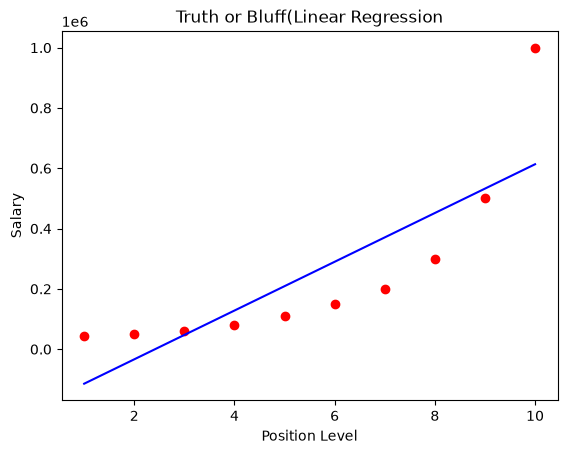

In [38]:
plt.scatter(X,y,color="red")
plt.plot(X,LR.predict(X),color="blue")
plt.title("Truth or Bluff(Linear Regression")
plt.xlabel("Position Level")
plt.ylabel("Salary")
plt.show()

# Visualising the Polynomial Regression results

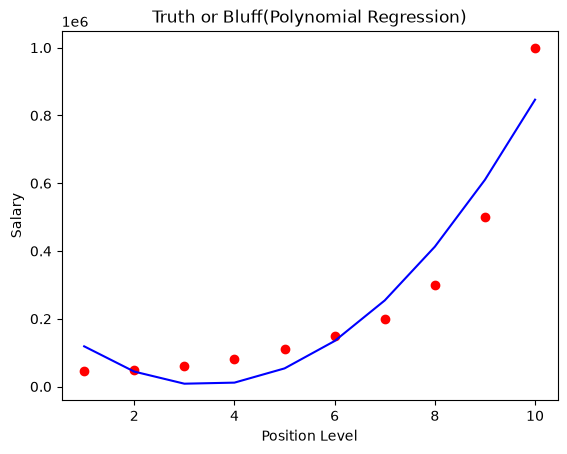

In [39]:
plt.scatter(X,y,color="red")
plt.plot(X,LR2.predict(X_poly),color="blue")
plt.title("Truth or Bluff(Polynomial Regression)")
plt.xlabel("Position Level")
plt.ylabel("Salary")
plt.show()

## Why does the graph change when the degree changes?

### Degree = 2

```python
poly = PolynomialFeatures(degree=2)
```

The computer creates

| Level | Level² |
|------:|--------:|
|1|1|
|2|4|
|3|9|
|4|16|
|5|25|

So the equation becomes

**$\hat{y}=b_0+b_1x+b_2x^2$**

The computer has **3 coefficients** to learn.

- **b₀**
- **b₁**
- **b₂**

Since there are fewer coefficients, the model has **less flexibility**.

So the curve is smoother and may not pass close to every data point.

---

### Degree = 4

```python
poly = PolynomialFeatures(degree=4)
```

The computer now creates

| Level | Level² | Level³ | Level⁴ |
|------:|--------:|--------:|--------:|
|1|1|1|1|
|2|4|8|16|
|3|9|27|81|
|4|16|64|256|
|5|25|125|625|

Now the equation becomes

**$\hat{y}=b_0+b_1x+b_2x^2+b_3x^3+b_4x^4$**

The computer now has **5 coefficients** to learn.

- **b₀**
- **b₁**
- **b₂**
- **b₃**
- **b₄**

Since there are more coefficients, the model has **more flexibility**.

So the curve bends more and passes closer to the data points.

---

## Final Conclusion ⭐

- **Degree = 2** → 3 coefficients → Less flexible curve.
- **Degree = 4** → 5 coefficients → More flexible curve.
- More coefficients allow the computer to fit the data more closely, so the **degree 4 graph fits the red points better** than the **degree 2 graph**.

## Can we keep increasing the polynomial degree?

Yes, we can try higher degrees, **but we should not increase the degree forever.**

Typical workflow:

```text
Degree = 1 (Linear Regression)

↓

Check performance

↓

Degree = 2

↓

Better?

↓

Degree = 3

↓

Better?

↓

Degree = 4

↓

Better?

↓

Stop when increasing the degree no longer gives significant improvement.
```

If we keep increasing the degree unnecessarily, the model may start **memorizing the training data** instead of learning the actual pattern. This is called **Overfitting**.

---

## Is Polynomial Regression a more perfect version of Linear Regression?

**No.**

It is better to say

> **Polynomial Regression is a more flexible version of Linear Regression, not a more perfect one.**

### Why?

- If the data follows a **straight-line relationship**, **Linear Regression** is the best choice.
- If the data follows a **curved (non-linear) relationship**, **Polynomial Regression** can model it better.

Using a very high polynomial degree on linear data only makes the model more complex and may reduce its performance on new data.

---

### Final Conclusion ⭐

- **Linear Regression** → Best for **linear relationships**.
- **Polynomial Regression** → Best for **non-linear (curved) relationships**.
- Polynomial Regression is **more flexible**, not always **better**.
- Choose the **smallest polynomial degree** that fits the data well without overfitting.

# Predicting a new result with Linear Regression

In [41]:
LR.predict([[6.5]])

array([330378.78787879])

In [44]:
LR2.predict([[1,6.5,42.25]])

array([189498.10606061])

In [46]:
LR2.predict(poly.fit_transform([[6.5]]))

array([189498.10606061])

# Visualising the Polynomial Regression results (for higher resolution and smoother curve)

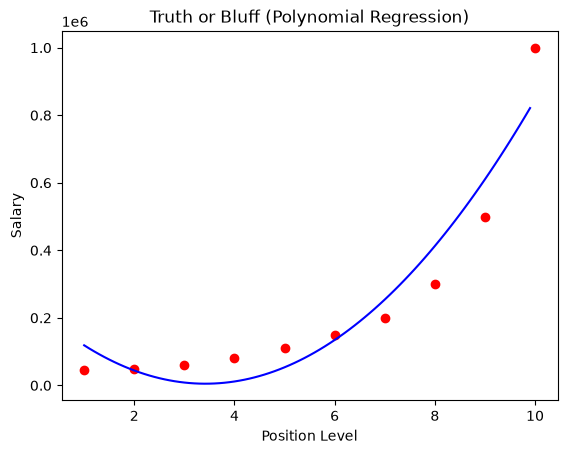

In [50]:


X_grid = np.arange(X.min(), X.max(), 0.1)
X_grid = X_grid.reshape((len(X_grid), 1))

plt.scatter(X, y, color='red')
plt.plot(X_grid, LR2.predict(poly.fit_transform(X_grid)), color='blue')

plt.title('Truth or Bluff (Polynomial Regression)')
plt.xlabel('Position Level')
plt.ylabel('Salary')

plt.show()